# 06 – Modellvergleich: Statistik vs. ML

**Ziel:** Alle Ergebnisse zusammenführen und die zentrale Vergleichstabelle erstellen.

**Stat-Baseline aus R (`statistik/analysis/05_survival_cox.qmd`):**

| Modell | Typ | C-Index |
|---|---|---|
| Cox PH statisch | semi-parametrisch | 0.756 |
| Cox PH zeitabhängig | semi-parametrisch | 0.986 (In-Sample) |

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import REPORTS

sns.set_theme(style='whitegrid')
print('Setup fertig.')

Setup fertig.


## 1. Alle ML-Ergebnisse laden

In [2]:
from src.evaluation.results import load_results, MODEL_ORDER

ml_results = load_results()
missing = [m for m in MODEL_ORDER if m not in ml_results]
if missing:
    print(f'Hinweis: noch keine Ergebnisse für {missing} – zugehöriges Notebook ausführen.')

df_ml = pd.DataFrame(ml_results).T
df_ml = df_ml[['RMSE', 'MAE', 'R²', 'NASA Score']].astype(float)
print(df_ml.to_string())

                     RMSE    MAE     R²  NASA Score
Random Forest       20.66  15.36  0.751      2011.9
XGBoost             20.45  15.21  0.756      1801.4
SVR (RBF)           21.12  15.73  0.740      1809.1
BiLSTM + Attention  13.33  10.05  0.896       265.4


## 2. Zentrale Vergleichstabelle (Stat + ML)

RMSE und MAE für Stat-Modelle sind nicht direkt vergleichbar  
(Cox PH gibt keine Punkt-RUL-Vorhersage). Der C-Index ist das faire Vergleichsmaß.

**Hinweis:** Cox C-Index 0.986 ist In-Sample (nicht kreuzvalidiert).  
ML C-Index wird auf dem echten Test-Set berechnet — methodisch strenger.

In [3]:
# Stat-Ergebnisse aus R (manuell eintragen)
stat_results = {
    'Cox PH (statisch)':    {'Typ': 'Stat – semi-param.', 'RMSE': '–',   'MAE': '–',   'R²': '–',    'NASA Score': '–',   'C-Index': '0.756', 'KI': 'Ja'},
    'Cox PH (zeitabhängig)':{'Typ': 'Stat – semi-param.', 'RMSE': '–',   'MAE': '–',   'R²': '–',    'NASA Score': '–',   'C-Index': '0.986*','KI': 'Ja'},
    'Weibull AFT':          {'Typ': 'Stat – parametrisch','RMSE': '–',   'MAE': '–',   'R²': '–',    'NASA Score': '–',   'C-Index': '–',     'KI': 'Ja'},
}

MODEL_TYPES = {
    'Random Forest':      'ML – baumbasiert',
    'XGBoost':            'ML – baumbasiert',
    'SVR (RBF)':          'ML – kernel',
    'BiLSTM + Attention': 'DL – sequenziell',
}

# ML-Ergebnisse
ml_rows = {}
for model, vals in ml_results.items():
    ml_rows[model] = {
        'Typ':        MODEL_TYPES.get(model, 'ML'),
        'RMSE':       vals['RMSE'],
        'MAE':        vals['MAE'],
        'R²':         vals['R²'],
        'NASA Score': vals['NASA Score'],
        'C-Index':    '–',   # TODO: optional via sksurv berechnen
        'KI':         'Nein',
    }

all_rows = {**stat_results, **ml_rows}
df_all = pd.DataFrame(all_rows).T
df_all.index.name = 'Modell'

print('\n=== Zentrale Vergleichstabelle ===')
print(df_all.to_string())
print('\n* In-Sample, nicht kreuzvalidiert')


=== Zentrale Vergleichstabelle ===
                                       Typ   RMSE    MAE     R² NASA Score C-Index    KI
Modell                                                                                  
Cox PH (statisch)       Stat – semi-param.      –      –      –          –   0.756    Ja
Cox PH (zeitabhängig)   Stat – semi-param.      –      –      –          –  0.986*    Ja
Weibull AFT            Stat – parametrisch      –      –      –          –       –    Ja
Random Forest             ML – baumbasiert  20.66  15.36  0.751     2011.9       –  Nein
XGBoost                   ML – baumbasiert  20.45  15.21  0.756     1801.4       –  Nein
SVR (RBF)                      ML – kernel  21.12  15.73   0.74     1809.1       –  Nein
BiLSTM + Attention        DL – sequenziell  13.33  10.05  0.896      265.4       –  Nein

* In-Sample, nicht kreuzvalidiert


## 3. Visualisierung: RMSE und NASA Score aller ML-Modelle

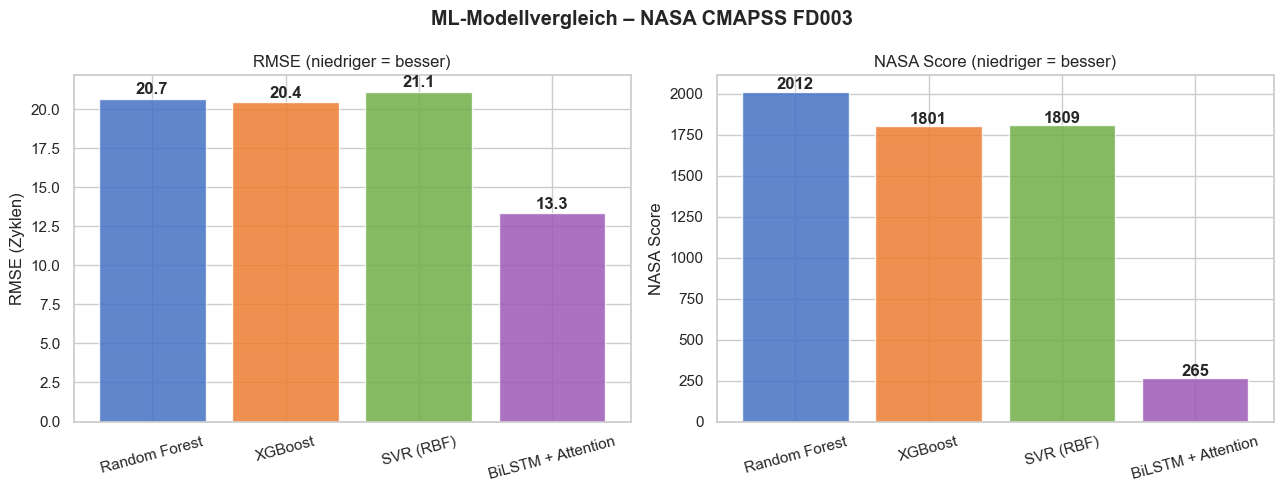

In [4]:
colors = {'Random Forest': '#4472C4', 'XGBoost': '#ED7D31',
          'SVR (RBF)': '#70AD47', 'BiLSTM + Attention': '#9B59B6'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
models = list(ml_results)

for ax, metric, title, offset in [
    (axes[0], 'RMSE',       'RMSE (niedriger = besser)',       0.3),
    (axes[1], 'NASA Score', 'NASA Score (niedriger = besser)', 15),
]:
    vals = [float(ml_results[m][metric]) for m in models]
    ax.bar(models, vals, color=[colors.get(m, 'grey') for m in models], alpha=0.85)
    for i, v in enumerate(vals):
        ax.text(i, v + offset, f'{v:.1f}' if metric == 'RMSE' else f'{v:.0f}',
                ha='center', fontweight='bold')
    ax.set_title(title)
    ax.set_ylabel('RMSE (Zyklen)' if metric == 'RMSE' else 'NASA Score')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('ML-Modellvergleich – NASA CMAPSS FD003', fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS / 'model_comparison.png', dpi=150)
plt.show()

## 4. Predicted vs. Actual – alle ML-Modelle nebeneinander

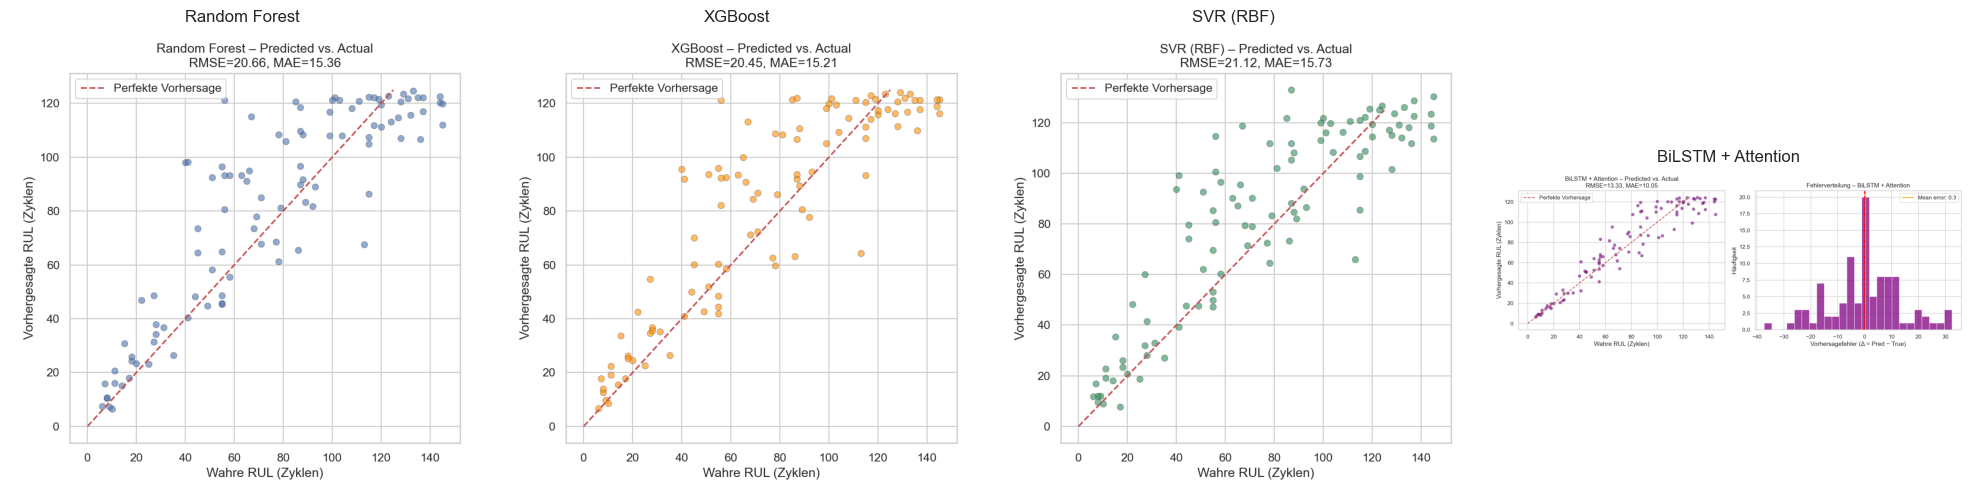

In [5]:
# Die Predicted-vs-Actual-Plots aus den einzelnen Notebooks nebeneinander zeigen
from PIL import Image

plot_files = [
    ('Random Forest',      REPORTS / 'rf_predicted_vs_actual.png'),
    ('XGBoost',            REPORTS / 'xgb_predicted_vs_actual.png'),
    ('SVR (RBF)',          REPORTS / 'svr_predicted_vs_actual.png'),
    ('BiLSTM + Attention', REPORTS / 'lstm_predicted_vs_actual.png'),
]

fig, axes = plt.subplots(1, len(plot_files), figsize=(5 * len(plot_files), 5))
for ax, (name, path) in zip(axes, plot_files):
    if path.exists():
        ax.imshow(Image.open(path))
        ax.set_title(name)
    else:
        ax.text(0.5, 0.5, f'{name}\nnoch nicht ausgeführt',
                ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

plt.tight_layout()
plt.savefig(REPORTS / 'all_predicted_vs_actual.png', dpi=150)
plt.show()

## 5. Schlussfolgerungen

*(Werte des Originallaufs (Juni 2026, Windows) aus `ml/reports/model_results_original.json`; die Tabelle oben zeigt den Neulauf auf macOS.)*

| Modell | RMSE Original | RMSE Neulauf | NASA Original | NASA Neulauf |
|---|---|---|---|---|
| Random Forest | 20.72 | 20.66 | 2051 | 2012 |
| XGBoost | 20.84 | 20.45 | 1941 | 1801 |
| SVR (RBF) | 21.12 | 21.12 | 1809 | 1809 |
| BiLSTM + Attention | 13.33 | 13.33 | 265 | 265 |

**Zentrale Erkenntnisse:**

1. **Die tabellarischen Modelle liegen gleichauf.** RF, XGBoost und SVR trennen weniger als 0.7 Zyklen RMSE. Das ist weniger als die Abweichung zwischen zwei Rechnern: Auf Windows (Originallauf) liegt RF vorn, auf macOS XGBoost. Auf demselben Feature-Set (36 Merkmale, Rolling-Fenster 5) begrenzt die Information, nicht der Algorithmus.

2. **Der NASA Score hängt an wenigen Engines.** Die fünf schlechtesten Vorhersagen machen 65–75 % des Scores aus. SVRs gutes Abschneiden beim NASA Score kommt von einem kleineren größten Fehler (+58.8 statt +65.2 Zyklen). Systematisch pessimistisch ist SVR nicht: Im Mittel liegt es sogar optimistischer als RF (+6.7 vs. +5.5 Zyklen).

3. **Das BiLSTM + Attention ist in allen vier Metriken am besten** (RMSE 13.33, NASA Score 265), auf beiden Plattformen identisch. Es macht keinen Fehler über +32.5 Zyklen. Einschränkung: Der Wert ist der beste von mehreren Trainingsläufen mit einem einzelnen Validierungssplit. Wie viel des Vorsprungs am längeren Zeitkontext liegt, zeigt Notebook 09 (rund 83 %).

4. **Statistik liefert, was ML nicht kann.** Konfidenzintervalle, Hazard Ratios und testbare Annahmen sind im regulatorischen Kontext (Luftfahrt) keine optionalen Extras.

5. **Der Cox C-Index von 0.986 ist In-Sample.** Ein fairer Vergleich erfordert kreuzvalidierte Scores. Diese methodische Einschränkung sollte transparent gemacht werden.

*Hinweis zur Evaluation:* Trainiert wird auf RUL gecappt bei 125, die wahre Test-RUL ist ungecappt (max. 145; 15 von 100 Engines liegen über 125). Das gilt für alle Modelle gleich und erhöht deren Fehler bei langlebigen Engines systematisch.